# Figure 7

In [1]:
from riskhistory.data import load_ddm_posterior, DATASET_LABELS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
FULL_MODEL = "HDDM_Base_Lag1-stpdrift_Pupil_stpdrift"

### Helper functions
`compute_ci` takes a posterior sample array (any shape, e.g. the raw
`(n_chains, n_draws)` arrays in the `.npz` files) and returns the mean plus
an equal-tailed 95% credible interval (2.5th/97.5th percentile of the pooled
draws). `build_param_ci_df` applies this to one model parameter's group-level
samples and every per-subject `_subj.{sub}` variant, for each dataset, and
stacks the results into a single dataframe.

In [2]:
posterior = load_ddm_posterior("HDDM_Base_Lag1-stpdrift_Pupil_boundary", "equalIndifference")

In [2]:
def compute_ci(samples, ci=95):
    """Mean + equal-tailed credible interval from pooled posterior draws."""
    samples = np.asarray(samples).flatten()
    lower_pct = (100 - ci) / 2
    upper_pct = 100 - lower_pct
    return {
        "mean": samples.mean(),
        "ci_low": np.percentile(samples, lower_pct),
        "ci_high": np.percentile(samples, upper_pct),
        "n_samples": samples.size,
    }


def build_param_ci_df(model_id, datasets, param, ci=95):
    """Group-level + per-subject credible intervals for one model parameter,
    stacked across datasets. Per-subject keys are named "{param}_subj.{sub}"
    in the posterior .npz files (see riskhistory.data.load_ddm_posterior)."""
    rows = []
    for ds in datasets:
        posterior = load_ddm_posterior(model_id, ds)

        group_stats = compute_ci(posterior[param], ci=ci)
        rows.append({"dataset": ds, "level": "group", "sub": np.nan, **group_stats})

        subj_prefix = f"{param}_subj."
        subj_keys = [k for k in posterior.files if k.startswith(subj_prefix)]
        for key in subj_keys:
            sub_id = int(key[len(subj_prefix):])
            subj_stats = compute_ci(posterior[key], ci=ci)
            rows.append({"dataset": ds, "level": "subject", "sub": sub_id, **subj_stats})

    return pd.DataFrame(rows)

### z_choice_prev1:pupil credible intervals
Group-level and per-subject 95% credible intervals for `z_choice_prev1:pupil`
(pupil modulation of the starting-point bias) from the full Stp-Drift-CH
model, across all three datasets.

In [3]:
zchoiceprev1_pupil_ci = build_param_ci_df(FULL_MODEL, DATASETS, "z_choice_prev1:pupil")

for ds in DATASETS:
    n_subs = ((zchoiceprev1_pupil_ci["dataset"] == ds) &
              (zchoiceprev1_pupil_ci["level"] == "subject")).sum()
    print(f"{ds}: {n_subs} subjects")

zchoiceprev1_pupil_ci

equalIndifference: 32 subjects
equalRange: 30 subjects
sheng2020: 63 subjects


,dataset,level,sub,mean,ci_low,ci_high,n_samples
0,equalIndifference,group,NaN,0.059082,0.014461,0.102119,32000
1,equalIndifference,subject,3.0,0.096368,0.000563,0.239760,32000
2,equalIndifference,subject,5.0,0.042450,-0.052036,0.122552,32000
3,equalIndifference,subject,11.0,0.053331,-0.044643,0.147136,32000
4,equalIndifference,subject,19.0,0.096576,0.010275,0.216914,32000
...,...,...,...,...,...,...,...
123,sheng2020,subject,87.0,0.045347,-0.035195,0.146526,32000
124,sheng2020,subject,88.0,0.020234,-0.066438,0.106741,32000
125,sheng2020,subject,90.0,0.031033,-0.047571,0.117197,32000
126,sheng2020,subject,92.0,0.019003,-0.064114,0.102797,32000


### Per-subject forest plot: z_choice_prev1:pupil
One row per subject (sorted by point estimate), colored by where its 95% CI
falls relative to 0: green if entirely above 0, red if entirely below 0,
grey if it includes 0. Group-level rows are excluded -- subjects only.

In [4]:
FOREST_COLORS = {
    "above": "#2CA02C",
    "includes": "#B0B0B0",
    "below": "#D62728",
}


def classify_ci(ci_low, ci_high):
    if ci_low > 0:
        return "above"
    if ci_high < 0:
        return "below"
    return "includes"


def plot_forest_panel(ax, df_subj, title, param_label, show_ylabel=False, show_xlabel=False):
    """Vertical line at 0; one row per subject with a dot (mean) and
    horizontal whisker (95% CI), sorted and colored by classify_ci()."""
    df_sorted = df_subj.sort_values("mean", ascending=False).reset_index(drop=True)
    y_pos = np.arange(len(df_sorted))

    ax.axvline(0, color="black", linewidth=1.5, linestyle="--", zorder=1)

    for y, row in zip(y_pos, df_sorted.itertuples()):
        color = FOREST_COLORS[classify_ci(row.ci_low, row.ci_high)]
        ax.plot([row.ci_low, row.ci_high], [y, y], color=color, linewidth=1.5, zorder=2)
        ax.scatter(row.mean, y, color=color, s=30, zorder=3,
                   edgecolor="black", linewidth=0.4)

    ax.set_ylim(len(df_sorted), -1)
    ax.set_yticks([])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.set_title(title)
    if show_ylabel:
        ax.set_ylabel("Subjects (sorted by estimate)")
    if show_xlabel:
        ax.set_xlabel(f"{param_label} (per-subject 95% CI)")

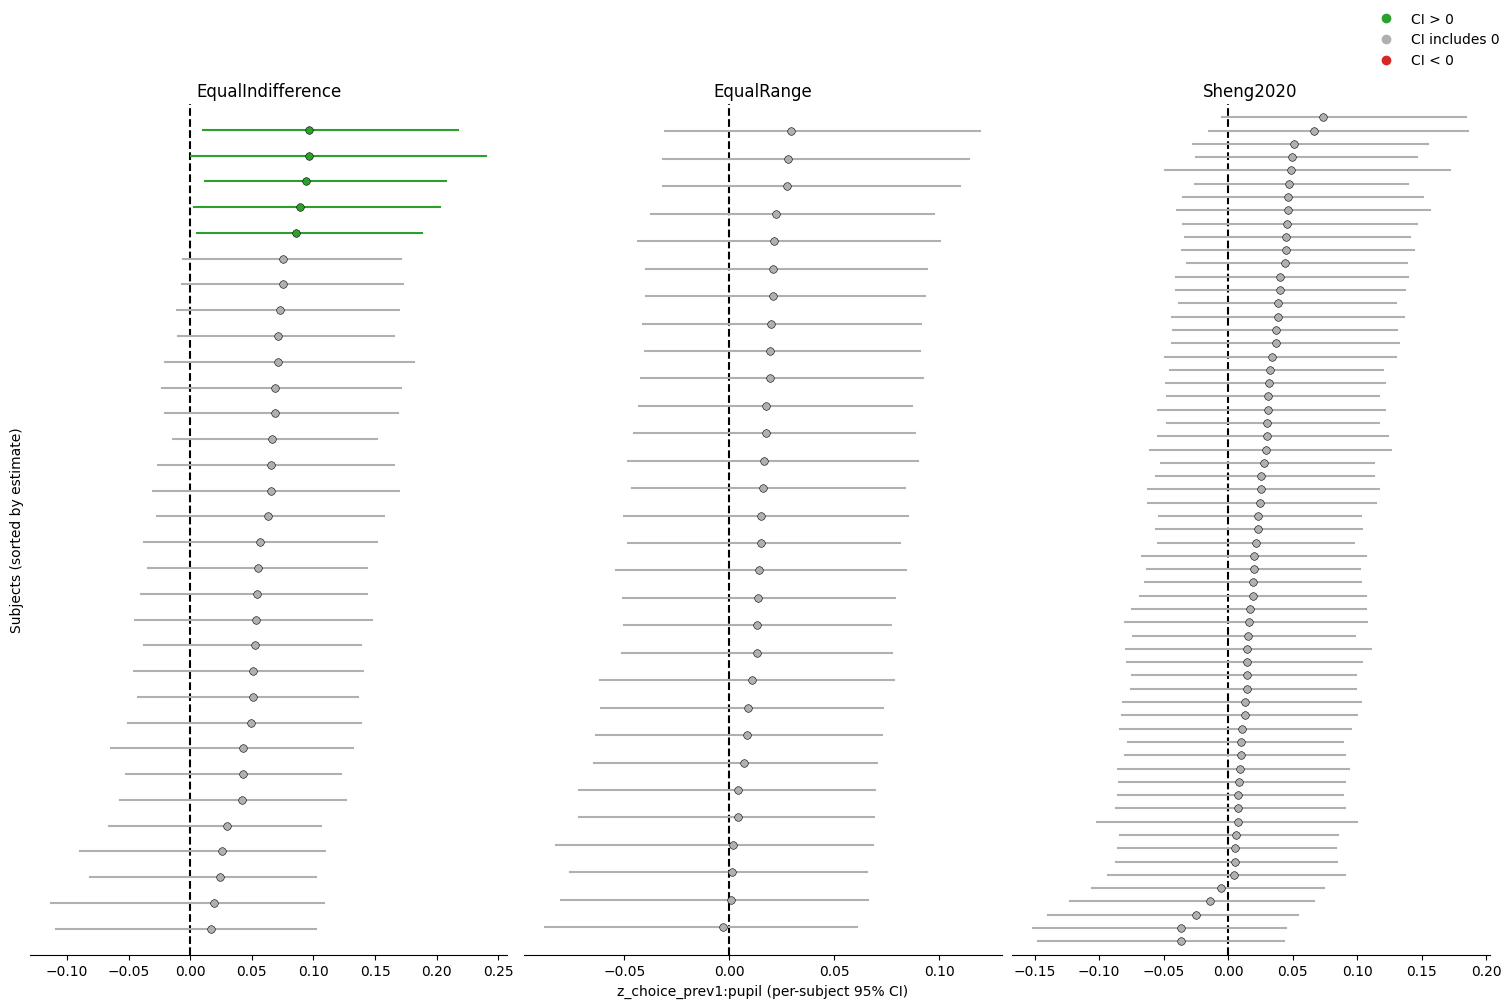

In [5]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 10), layout="constrained")

for col, ds in enumerate(DATASETS):
    df_subj = zchoiceprev1_pupil_ci[
        (zchoiceprev1_pupil_ci["dataset"] == ds) &
        (zchoiceprev1_pupil_ci["level"] == "subject")
    ]
    plot_forest_panel(axes[col], df_subj, DATASET_LABELS.get(ds, ds),
                      "z_choice_prev1:pupil",
                      show_ylabel=(col == 0), show_xlabel=(col == 1))

legend_handles = [
    plt.Line2D([0], [0], marker="o", color=FOREST_COLORS["above"], linestyle="", label="CI > 0"),
    plt.Line2D([0], [0], marker="o", color=FOREST_COLORS["includes"], linestyle="", label="CI includes 0"),
    plt.Line2D([0], [0], marker="o", color=FOREST_COLORS["below"], linestyle="", label="CI < 0"),
]
fig.legend(handles=legend_handles, loc="outside upper right", frameon=False)

fig.savefig("saved/figure7.svg", dpi=300, bbox_inches="tight")
plt.show()

### v_choice_prev1:pupil credible intervals
Group-level and per-subject 95% credible intervals for `v_choice_prev1:pupil`
(pupil modulation of the drift bias) from the full Stp-Drift-CH model,
across all three datasets.

In [6]:
vchoiceprev1_pupil_ci = build_param_ci_df(FULL_MODEL, DATASETS, "v_choice_prev1:pupil")
vchoiceprev1_pupil_ci

,dataset,level,sub,mean,ci_low,ci_high,n_samples
0,equalIndifference,group,NaN,-0.071587,-0.117006,-0.020755,32000
1,equalIndifference,subject,3.0,-0.074527,-0.162993,0.007261,32000
2,equalIndifference,subject,5.0,-0.082001,-0.173517,-0.007386,32000
3,equalIndifference,subject,11.0,-0.085038,-0.189211,-0.007927,32000
4,equalIndifference,subject,19.0,-0.058450,-0.129322,0.041698,32000
...,...,...,...,...,...,...,...
123,sheng2020,subject,87.0,-0.043505,-0.140041,0.077841,32000
124,sheng2020,subject,88.0,-0.052913,-0.154712,0.060215,32000
125,sheng2020,subject,90.0,-0.058645,-0.159201,0.045549,32000
126,sheng2020,subject,92.0,-0.064253,-0.173988,0.039762,32000


### Per-subject forest plot: v_choice_prev1:pupil
Same layout as the `z_choice_prev1:pupil` forest plot above.

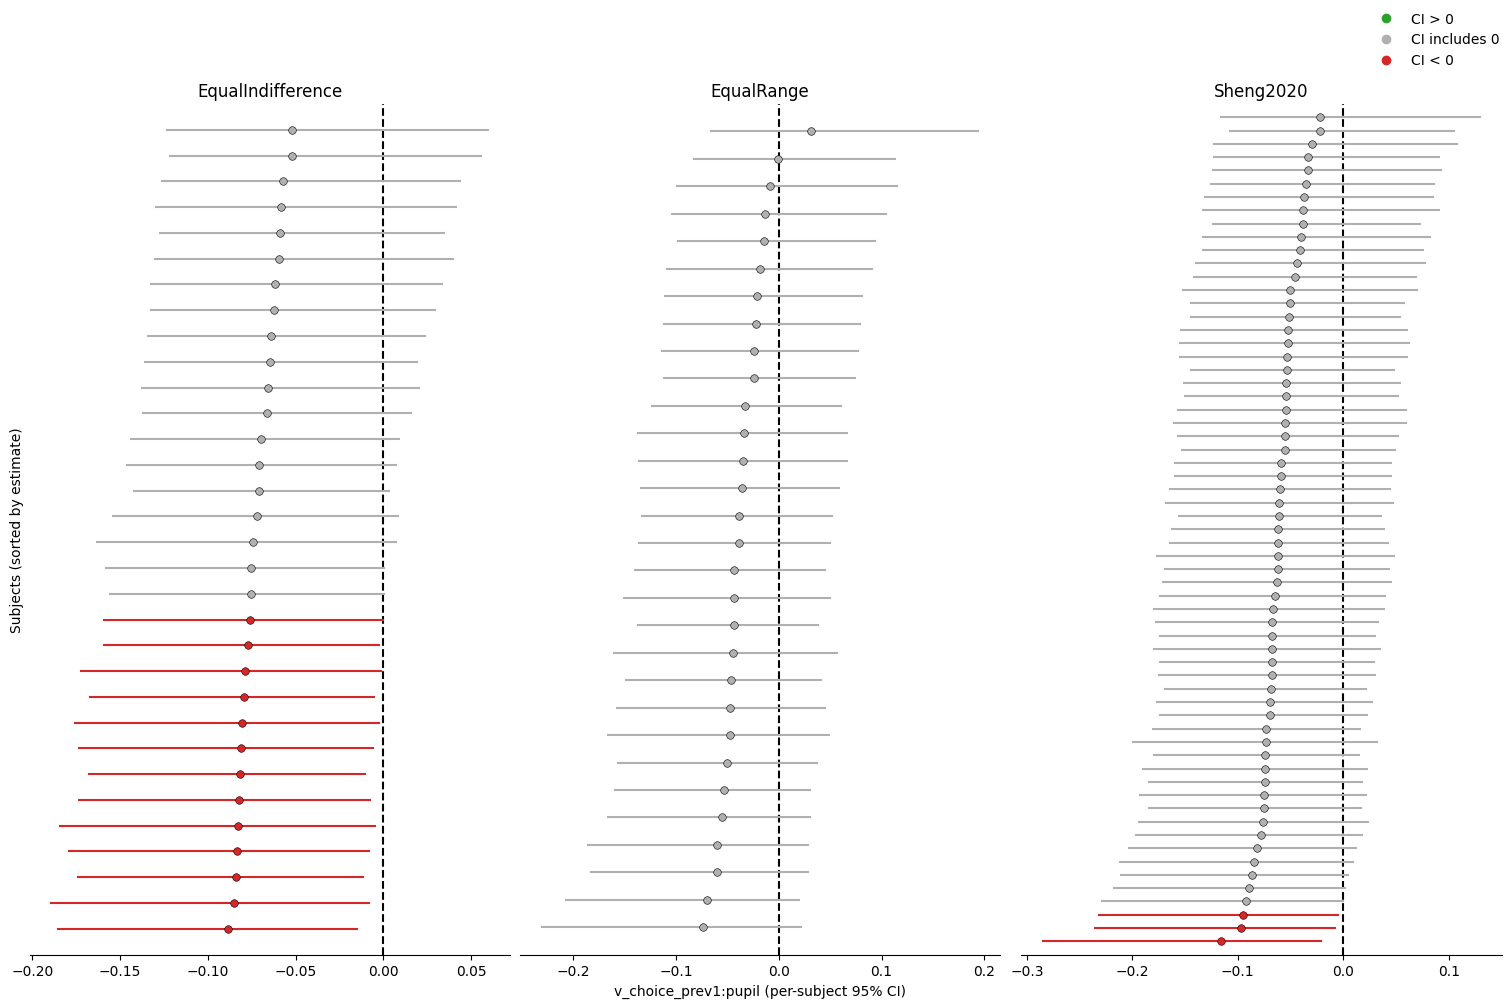

In [7]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 10), layout="constrained")

for col, ds in enumerate(DATASETS):
    df_subj = vchoiceprev1_pupil_ci[
        (vchoiceprev1_pupil_ci["dataset"] == ds) &
        (vchoiceprev1_pupil_ci["level"] == "subject")
    ]
    plot_forest_panel(axes[col], df_subj, DATASET_LABELS.get(ds, ds),
                      "v_choice_prev1:pupil",
                      show_ylabel=(col == 0), show_xlabel=(col == 1))

legend_handles = [
    plt.Line2D([0], [0], marker="o", color=FOREST_COLORS["above"], linestyle="", label="CI > 0"),
    plt.Line2D([0], [0], marker="o", color=FOREST_COLORS["includes"], linestyle="", label="CI includes 0"),
    plt.Line2D([0], [0], marker="o", color=FOREST_COLORS["below"], linestyle="", label="CI < 0"),
]
fig.legend(handles=legend_handles, loc="outside upper right", frameon=False)

fig.savefig("saved/figure7_v.svg", dpi=300, bbox_inches="tight")
plt.show()

### z_pupil credible intervals
Group-level and per-subject 95% credible intervals for `z_pupil`
(pupil's main effect on the starting-point bias) from the full Stp-Drift-CH model, across all three datasets.

In [ ]:
z_pupil_ci = build_param_ci_df(FULL_MODEL, DATASETS, "z_pupil")
z_pupil_ci

### Per-subject forest plot: z_pupil
Same layout as the `z_choice_prev1:pupil` forest plot above.

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 10), layout="constrained")

for col, ds in enumerate(DATASETS):
    df_subj = z_pupil_ci[
        (z_pupil_ci["dataset"] == ds) &
        (z_pupil_ci["level"] == "subject")
    ]
    plot_forest_panel(axes[col], df_subj, DATASET_LABELS.get(ds, ds),
                      "z_pupil",
                      show_ylabel=(col == 0), show_xlabel=(col == 1))

legend_handles = [
    plt.Line2D([0], [0], marker="o", color=FOREST_COLORS["above"], linestyle="", label="CI > 0"),
    plt.Line2D([0], [0], marker="o", color=FOREST_COLORS["includes"], linestyle="", label="CI includes 0"),
    plt.Line2D([0], [0], marker="o", color=FOREST_COLORS["below"], linestyle="", label="CI < 0"),
]
fig.legend(handles=legend_handles, loc="outside upper right", frameon=False)

fig.savefig("saved/figure7_zpupil.svg", dpi=300, bbox_inches="tight")
plt.show()

### v_pupil credible intervals
Group-level and per-subject 95% credible intervals for `v_pupil`
(pupil's main effect on the drift rate) from the full Stp-Drift-CH model, across all three datasets.

In [ ]:
v_pupil_ci = build_param_ci_df(FULL_MODEL, DATASETS, "v_pupil")
v_pupil_ci

### Per-subject forest plot: v_pupil
Same layout as the `z_choice_prev1:pupil` forest plot above.

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 10), layout="constrained")

for col, ds in enumerate(DATASETS):
    df_subj = v_pupil_ci[
        (v_pupil_ci["dataset"] == ds) &
        (v_pupil_ci["level"] == "subject")
    ]
    plot_forest_panel(axes[col], df_subj, DATASET_LABELS.get(ds, ds),
                      "v_pupil",
                      show_ylabel=(col == 0), show_xlabel=(col == 1))

legend_handles = [
    plt.Line2D([0], [0], marker="o", color=FOREST_COLORS["above"], linestyle="", label="CI > 0"),
    plt.Line2D([0], [0], marker="o", color=FOREST_COLORS["includes"], linestyle="", label="CI includes 0"),
    plt.Line2D([0], [0], marker="o", color=FOREST_COLORS["below"], linestyle="", label="CI < 0"),
]
fig.legend(handles=legend_handles, loc="outside upper right", frameon=False)

fig.savefig("saved/figure7_vpupil.svg", dpi=300, bbox_inches="tight")
plt.show()